In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

In [2]:
west = pd.read_csv("species_west.csv", index_col=0)
east = pd.read_csv("species_east.csv", index_col=0)

In [3]:
print(west.shape)

print(east.shape)

print(west.columns.to_list())
print(east.columns.to_list())

(7997, 26)
(4168, 26)
['gbifID', 'decimalLongitude', 'decimalLatitude', 'wc2.1_30s_bio_10', 'wc2.1_30s_bio_15', 'wc2.1_30s_bio_18', 'wc2.1_30s_bio_19', 'wc2.1_30s_bio_6', 'wc2.1_30s_bio_9', 'Aspect', 'Curvature', 'EVI', 'SAVI', 'BSI', 'Slope', 'Snow_Duration_Pct', 'Soil_Clay', 'Soil_Organic_Carbon', 'Soil_pH', 'Soil_Sand', 'Topo_Solar_Radiation_MJ', 'TRI', 'TWI', 'true_present', 'species', 'Cluster']
['gbifID', 'decimalLongitude', 'decimalLatitude', 'wc2.1_30s_bio_10', 'wc2.1_30s_bio_15', 'wc2.1_30s_bio_18', 'wc2.1_30s_bio_19', 'wc2.1_30s_bio_6', 'wc2.1_30s_bio_9', 'Aspect', 'Curvature', 'EVI', 'SAVI', 'BSI', 'Slope', 'Snow_Duration_Pct', 'Soil_Clay', 'Soil_Organic_Carbon', 'Soil_pH', 'Soil_Sand', 'Topo_Solar_Radiation_MJ', 'TRI', 'TWI', 'true_present', 'species', 'Cluster']


In [4]:
climatic_cols = west.columns.to_list()[3:-3]
print(climatic_cols)

['wc2.1_30s_bio_10', 'wc2.1_30s_bio_15', 'wc2.1_30s_bio_18', 'wc2.1_30s_bio_19', 'wc2.1_30s_bio_6', 'wc2.1_30s_bio_9', 'Aspect', 'Curvature', 'EVI', 'SAVI', 'BSI', 'Slope', 'Snow_Duration_Pct', 'Soil_Clay', 'Soil_Organic_Carbon', 'Soil_pH', 'Soil_Sand', 'Topo_Solar_Radiation_MJ', 'TRI', 'TWI']


In [5]:
species_all = pd.concat([west, east], ignore_index=True)
#print(species_all.species.value_counts())
# odrzucam te poniżej 500 obserwacji
mask = species_all["species"].value_counts() > 500
species_all = species_all[species_all["species"].isin(mask[mask].index)]
print(species_all.species.value_counts())

species
Linaria alpina           3330
Armeria alpina           1053
Sibbaldia procumbens      957
Carex myosuroides         822
Carex parviflora          814
Petrocallis pyrenaica     672
Astragalus alpinus        617
Kalmia procumbens         538
Erigeron alpinus          528
Name: count, dtype: int64


In [6]:
# losowe punkty
background = pd.read_csv("../output/features/pseudo_absence.csv")
background.head()

,gbifID,decimalLongitude,decimalLatitude,wc2.1_30s_bio_10,wc2.1_30s_bio_15,wc2.1_30s_bio_18,wc2.1_30s_bio_19,wc2.1_30s_bio_6,wc2.1_30s_bio_9,Aspect,...,Slope,Snow_Duration_Pct,Soil_Clay,Soil_Organic_Carbon,Soil_pH,Soil_Sand,Topo_Solar_Radiation_MJ,TRI,TWI,true_present
0,pseudo_2,13.697968,46.325520,16.500000,23.966074,570,448,-6.3,-0.450000,224.0,...,22.0,0.0,255.0,1327.0,54.0,250.0,0.891549,0.250,7.493905,0
1,pseudo_3,8.516397,46.279167,12.183333,24.661802,373,204,-5.9,-1.933333,85.0,...,39.0,0.0,191.0,907.0,53.0,463.0,0.577664,1.500,7.402440,0
2,pseudo_4,14.482414,47.542547,12.933333,31.827656,453,212,-7.9,-3.600000,227.0,...,26.0,0.0,277.0,1192.0,51.0,293.0,0.871590,0.625,7.834172,0
3,pseudo_5,7.162609,44.614140,11.000000,18.697920,229,296,-6.8,10.783334,214.0,...,24.0,36.0,207.0,1090.0,55.0,378.0,0.991181,3.375,8.516088,0
4,pseudo_6,8.102843,45.908615,12.049999,24.043575,244,158,-6.2,-2.150000,328.0,...,46.0,77.0,209.0,1254.0,56.0,427.0,0.716958,0.500,7.468302,0


In [7]:
species_all.iloc[[559, 4140]] # przykład rekordu, gdzie mamy różne gatunki w tych samych współrzędnych
# to znaczy, że użytkownicy najpewniej nie rozróżnili gatunków

,gbifID,decimalLongitude,decimalLatitude,wc2.1_30s_bio_10,wc2.1_30s_bio_15,wc2.1_30s_bio_18,wc2.1_30s_bio_19,wc2.1_30s_bio_6,wc2.1_30s_bio_9,Aspect,...,Soil_Clay,Soil_Organic_Carbon,Soil_pH,Soil_Sand,Topo_Solar_Radiation_MJ,TRI,TWI,true_present,species,Cluster
565,3933193948,6.45088,45.99959,9.516666,17.252876,357,508,-7.6,9.516666,337.0,...,203.0,1137.0,56.0,353.0,0.739542,2.375,8.176017,1,Armeria alpina,West
6084,3933527849,6.45088,45.99959,9.516666,17.252876,357,508,-7.6,9.516666,337.0,...,203.0,1137.0,56.0,353.0,0.739542,2.375,8.176017,1,Linaria alpina,West


In [8]:
# łaczmy duplikaty do jednego rekordu (gbifID różne gbifID, ale te same współrzędne i gatunek)
print(species_all.shape)
species_all.drop_duplicates(subset=["decimalLongitude", "decimalLatitude", "species"], inplace=True)
print(species_all.shape)

(9331, 26)
(8932, 26)


In [9]:
# to jest raczej niemożliwe, ale sprawdźmy z ciekawości czy losowe punkty też się powtórzyły
print(background.shape)
background.drop_duplicates(subset=["decimalLongitude", "decimalLatitude"], inplace=True)
print(background.shape)

(11983, 24)
(11983, 24)


# absencje

Poniższe podejścia pewnie można jakoś sformalizować, ale narazie zostawiam szkic.

## pierwsze podejście
```
Założenie:
	organizmy nie wchodzą ze sobą w interakcje ekologiczne.
	tzn. wystąpienie jednego gatunku nie wpływa na obecność drugiego.

Implikacje:
	Jeżeli w obszarze $x$ obserwujemy wystąpienie gatunku $A$, to mamy pewność, że był tam obserwator.
	Jeżeli w tym samym obszarze $x$ nie obserwujemy wystąpienia $B$ to mamy "pewność", że go tam nie ma. Możemy przypisać '0'.
```
## drugie podejście

```
Poprawka do pierwszego:
	Jeżeli organizmy klastrują się wyjątkowo dobrze jeżeli chodzi o zmienne klimatyczne, ale korelują ze sobą często przestrzennie,
	to może to oznaczać, że wchodzą ze sobą w interakcje.

Zamiast 0 przypiszemy jakąś wartość 0-1 w zależności od charakteru korelacji.
```

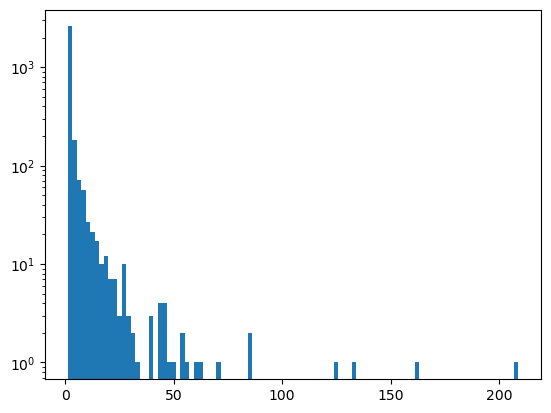

In [10]:
# klastrujemy obserwacje w obszary obserwacji, po współrzędnych geograficznych
# dbscan

from sklearn.cluster import DBSCAN
eps = 0.5/6371.0 # 0.5 km w radianach
dbscan = DBSCAN(eps=eps, min_samples=1,  metric='haversine') # metryka do danych geograficznych
# min_samples = 1, nie chcemy odrzucać samotnych punktów
clusters = dbscan.fit_predict(np.radians(species_all[["decimalLatitude", "decimalLongitude"]]))
tags, counts = np.unique(clusters, return_counts=True)
plt.hist(counts, bins=100)
plt.yscale("log")

In [11]:
print(tags.shape)
print(species_all.shape)

(3050,)
(8932, 26)


In [12]:
species_all["cluster"] = clusters
cluster_pd = pd.DataFrame({"cluster": tags, "count": counts})

cluster_pd.head()

,cluster,count
0,0,30
1,1,1
2,2,1
3,3,5
4,4,1


In [13]:
species_all["east_west"] = (species_all["Cluster"] == "East").astype(int) - (species_all["Cluster"] == "West").astype(int)
try:
	species_all.drop(columns=["gbifID", "Cluster", "true_present"], inplace=True)
except KeyError:
	pass


species_all = species_all.merge(cluster_pd, on="cluster", how="inner")
species_all[species_all.cluster == 3]

,decimalLongitude,decimalLatitude,wc2.1_30s_bio_10,wc2.1_30s_bio_15,wc2.1_30s_bio_18,wc2.1_30s_bio_19,wc2.1_30s_bio_6,wc2.1_30s_bio_9,Aspect,Curvature,...,Soil_Organic_Carbon,Soil_pH,Soil_Sand,Topo_Solar_Radiation_MJ,TRI,TWI,species,cluster,east_west,count
3,6.953128,44.694893,9.133333,22.033592,212,325,-9.3,8.866667,220.0,13.009056,...,1282.0,60.0,384.0,0.970823,1.875,8.856396,Armeria alpina,3,-1,5
7,6.951450,44.695988,9.133333,22.033592,212,325,-9.3,8.866667,220.0,3.719488,...,1282.0,60.0,384.0,0.984753,0.125,8.745118,Armeria alpina,3,-1,5
16,6.951978,44.695683,9.133333,22.033592,212,325,-9.3,8.866667,196.0,13.004448,...,1282.0,60.0,384.0,0.905282,1.250,9.444089,Armeria alpina,3,-1,5
17,6.951092,44.695968,9.133333,22.033592,212,325,-9.3,8.866667,218.0,16.107153,...,1282.0,60.0,384.0,0.970454,3.000,8.854754,Armeria alpina,3,-1,5
18,6.951547,44.695969,9.133333,22.033592,212,325,-9.3,8.866667,204.0,5.988356,...,1282.0,60.0,384.0,0.949664,0.625,8.978255,Armeria alpina,3,-1,5


In [14]:
# sprawdzmy czy miejsca obserwacji sie nie powtarzają
species_all[species_all[["decimalLongitude", "decimalLatitude"]].duplicated(keep=False)].sort_values(by=["decimalLongitude", "decimalLatitude"])

,decimalLongitude,decimalLatitude,wc2.1_30s_bio_10,wc2.1_30s_bio_15,wc2.1_30s_bio_18,wc2.1_30s_bio_19,wc2.1_30s_bio_6,wc2.1_30s_bio_9,Aspect,Curvature,...,Soil_Organic_Carbon,Soil_pH,Soil_Sand,Topo_Solar_Radiation_MJ,TRI,TWI,species,cluster,east_west,count
599,5.477040,44.829310,13.100000,20.061270,263,357,-5.2,13.100000,0.0,1.300135,...,1029.0,63.0,364.0,0.862994,0.125,10.499577,Armeria alpina,178,-1,3
2772,5.477040,44.829310,13.100000,20.061270,263,357,-5.2,13.100000,0.0,1.300135,...,1029.0,63.0,364.0,0.862994,0.125,10.499577,Erigeron alpinus,178,-1,3
735,5.510190,44.789540,12.683333,21.092636,262,370,-5.7,12.683333,263.0,10.577443,...,1085.0,62.0,392.0,0.963954,0.500,8.717655,Armeria alpina,211,-1,2
2855,5.510190,44.789540,12.683333,21.092636,262,370,-5.7,12.683333,263.0,10.577443,...,1085.0,62.0,392.0,0.963954,0.500,8.717655,Erigeron alpinus,211,-1,2
521,5.522370,44.887740,11.433333,20.426407,291,405,-6.3,11.366667,297.0,4.356355,...,955.0,59.0,374.0,0.917103,1.625,8.595987,Armeria alpina,89,-1,124
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6698,13.647778,47.487222,4.983333,19.068844,588,365,-11.7,-8.033333,292.0,3.756717,...,1208.0,53.0,351.0,0.763253,0.750,9.138828,Linaria alpina,1870,1,9
5844,14.264722,47.661111,8.783334,23.321102,580,334,-9.0,-5.050000,43.0,7.186920,...,997.0,52.0,376.0,0.633023,3.125,8.937199,Armeria alpina,1559,1,8
6462,14.264722,47.661111,8.783334,23.321102,580,334,-9.0,-5.050000,43.0,7.186920,...,997.0,52.0,376.0,0.633023,3.125,8.937199,Carex parviflora,1559,1,8
5982,14.766247,46.506394,9.083333,19.727556,528,332,-9.2,-5.050000,316.0,3.049699,...,1066.0,53.0,353.0,0.734094,1.000,7.878571,Armeria alpina,1633,1,11


In [15]:
# do cluster_pd dodajemy kolumny dla każdego gatunku, z informacją o tym czy występuje w danym klastrze
# w tym samym czasie dodajemy kolumnę z wartswami bioklimatycznymi
# dla klastru będzie to średnia wartość bioklimatyczna dla wszystkich obserwacji w klastrze
# można wymyślić coś lepszego, np nie tylko średnia, ale też odchylenie itp, ale na razie zostawiamy tylko średnią
for species in species_all["species"].unique():
	cluster_pd[species] = cluster_pd["cluster"].apply(lambda x: int(species in species_all[species_all["cluster"] == x]["species"].unique()))

cluster_pd.head()

,cluster,count,Armeria alpina,Astragalus alpinus,Carex myosuroides,Carex parviflora,Erigeron alpinus,Linaria alpina,Kalmia procumbens,Petrocallis pyrenaica,Sibbaldia procumbens
0,0,30,1,1,1,1,1,0,0,0,1
1,1,1,1,0,0,0,0,0,0,0,0
2,2,1,1,0,0,0,0,0,0,0,0
3,3,5,1,0,0,0,0,0,0,0,0
4,4,1,1,0,0,0,0,0,0,0,0


<Axes: >

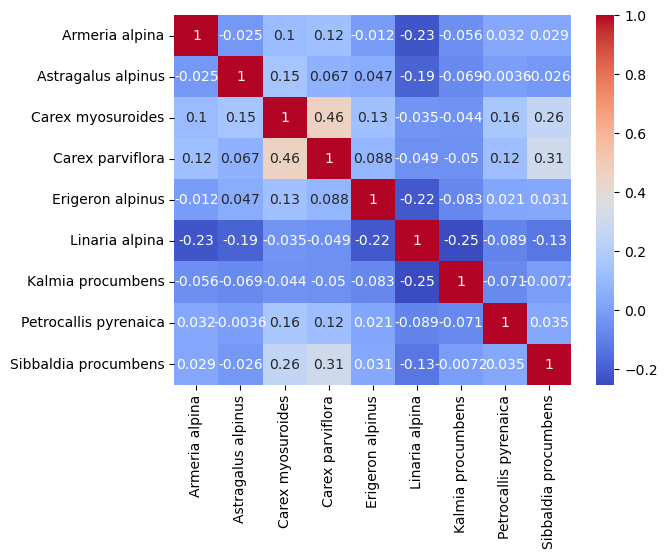

In [16]:
# sprawdzamy jak często gatunki występują razem w klastrach
sns.heatmap(cluster_pd[species_all["species"].unique()].corr(), annot=True, cmap="coolwarm")

Zapamiętajmy narazie te korelacje, potem może je uwzględnimy.

In [17]:
# dodajemy kolumny bioklimatyczne do cluster_pd, jako średnie wartości dla klastrów
for col in climatic_cols:
	cluster_pd[col] = cluster_pd["cluster"].apply(lambda x: species_all[species_all["cluster"] == x][col].mean())

In [18]:
cluster_pd.iloc()[:1]

,cluster,count,Armeria alpina,Astragalus alpinus,Carex myosuroides,Carex parviflora,Erigeron alpinus,Linaria alpina,Kalmia procumbens,Petrocallis pyrenaica,...,BSI,Slope,Snow_Duration_Pct,Soil_Clay,Soil_Organic_Carbon,Soil_pH,Soil_Sand,Topo_Solar_Radiation_MJ,TRI,TWI
0,0,30,1,1,1,1,1,0,0,0,...,-0.04126,18.0,75.133333,186.7,1217.5,60.0,418.2,0.889837,1.6875,8.987008


# Przewidujmy!

In [19]:
# teraz napiszmy model, który przewiduje wektor prawdopodobieństw

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
#kfold

model = RandomForestClassifier(n_estimators=100, random_state=42)
X = cluster_pd.drop(columns=["cluster", "count"] + species_all["species"].unique().tolist())
y = cluster_pd[species_all["species"].unique()].values
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print(classification_report(y_test, y_pred, target_names=species_all["species"].unique().tolist()))

                       precision    recall  f1-score   support

       Armeria alpina       0.91      0.24      0.38        42
   Astragalus alpinus       1.00      0.05      0.09        43
    Carex myosuroides       1.00      0.21      0.35        33
     Carex parviflora       0.83      0.14      0.23        37
     Erigeron alpinus       1.00      0.02      0.04        47
       Linaria alpina       0.72      0.78      0.75       167
    Kalmia procumbens       0.62      0.25      0.36        20
Petrocallis pyrenaica       0.00      0.00      0.00        23
 Sibbaldia procumbens       0.86      0.32      0.46        38

            micro avg       0.75      0.38      0.51       450
            macro avg       0.77      0.22      0.30       450
         weighted avg       0.79      0.38      0.43       450
          samples avg       0.51      0.43      0.45       450



/home/michnal/miniforge3/envs/binf2/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/michnal/miniforge3/envs/binf2/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in samples with no predicted labels. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


In [22]:
# to co wyżej + background
cluster_pd_bg = cluster_pd.copy()
cluster_pd_bg = pd.concat([cluster_pd_bg, background[climatic_cols]], ignore_index=True)
cluster_pd_bg.head()

,cluster,count,Armeria alpina,Astragalus alpinus,Carex myosuroides,Carex parviflora,Erigeron alpinus,Linaria alpina,Kalmia procumbens,Petrocallis pyrenaica,...,BSI,Slope,Snow_Duration_Pct,Soil_Clay,Soil_Organic_Carbon,Soil_pH,Soil_Sand,Topo_Solar_Radiation_MJ,TRI,TWI
0,0.0,30.0,1.0,1.0,1.0,1.0,1.0,0.0,0.0,0.0,...,-0.041260,18.0,75.133333,186.7,1217.5,60.0,418.2,0.889837,1.6875,8.987008
1,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,-0.034230,9.0,66.000000,178.0,1090.0,61.0,414.0,0.914754,0.2500,9.353432
2,2.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.078896,18.0,85.000000,207.0,1242.0,62.0,406.0,0.873721,0.8750,8.975715
3,3.0,5.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,-0.172014,16.4,70.400000,174.0,1282.0,60.0,384.0,0.956195,1.3750,8.975723
4,4.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.011744,22.0,86.000000,136.0,1147.0,61.0,422.0,0.687109,0.2500,8.834476


In [23]:
cluster_pd_bg
# replace nans with 0 in species columns
for species in species_all["species"].unique():
	cluster_pd_bg[species] = cluster_pd_bg[species].fillna(0)
# drop cluster
cluster_pd_bg.head()

,cluster,count,Armeria alpina,Astragalus alpinus,Carex myosuroides,Carex parviflora,Erigeron alpinus,Linaria alpina,Kalmia procumbens,Petrocallis pyrenaica,...,BSI,Slope,Snow_Duration_Pct,Soil_Clay,Soil_Organic_Carbon,Soil_pH,Soil_Sand,Topo_Solar_Radiation_MJ,TRI,TWI
0,0.0,30.0,1.0,1.0,1.0,1.0,1.0,0.0,0.0,0.0,...,-0.041260,18.0,75.133333,186.7,1217.5,60.0,418.2,0.889837,1.6875,8.987008
1,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,-0.034230,9.0,66.000000,178.0,1090.0,61.0,414.0,0.914754,0.2500,9.353432
2,2.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.078896,18.0,85.000000,207.0,1242.0,62.0,406.0,0.873721,0.8750,8.975715
3,3.0,5.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,-0.172014,16.4,70.400000,174.0,1282.0,60.0,384.0,0.956195,1.3750,8.975723
4,4.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.011744,22.0,86.000000,136.0,1147.0,61.0,422.0,0.687109,0.2500,8.834476


In [24]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
#kfold

model = RandomForestClassifier(n_estimators=100, random_state=42)
X = cluster_pd_bg.drop(columns = species_all["species"].unique().tolist())
y = cluster_pd_bg[species_all["species"].unique()].values
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print(classification_report(y_test, y_pred, target_names=species_all["species"].unique().tolist()))

                       precision    recall  f1-score   support

       Armeria alpina       1.00      0.65      0.79        40
   Astragalus alpinus       1.00      0.46      0.63        39
    Carex myosuroides       0.94      0.52      0.67        29
     Carex parviflora       1.00      0.38      0.55        29
     Erigeron alpinus       0.86      0.21      0.33        29
       Linaria alpina       0.94      0.90      0.92       182
    Kalmia procumbens       1.00      0.79      0.88        28
Petrocallis pyrenaica       1.00      0.35      0.52        20
 Sibbaldia procumbens       0.93      0.39      0.55        33

            micro avg       0.96      0.66      0.78       429
            macro avg       0.96      0.52      0.65       429
         weighted avg       0.96      0.66      0.75       429
          samples avg       0.16      0.15      0.15       429



/home/michnal/miniforge3/envs/binf2/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in samples with no predicted labels. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/michnal/miniforge3/envs/binf2/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in samples with no true labels. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/michnal/miniforge3/envs/binf2/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in samples with no true nor predicted labels. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric